# Parte 04 · Preprocesamiento y selección de K — Dataset: Suicidios

**Proyecto final · Minería de Datos 1 · Grupo #2**  
**Responsable:** Desmond Bermúdez Rodríguez  
**Entrada:** `data/processed/suicidio_limpio.csv`, generado en la Parte 01.

**¿Qué hacemos en esta parte?** Preparamos observaciones comparables de país y año,
justificamos las variables, transformamos y estandarizamos sus escalas y entrenamos
14 alternativas de K-Means en tres rangos de K. La Parte 05 retoma exactamente esta
preparación para evaluar la estabilidad e interpretar los perfiles.

**Contenido**
1. Librerías y revisión del dataset limpio.
2. Unidad de análisis y selección de variables.
3. Atípicos, transformación logarítmica y estandarización.
4. Modelos con K de 2 a 15 y referencia K=1.
5. Comparación gráfica, selección y conclusiones.

Ejecutar las celdas de principio a fin con las dependencias de `requirements.txt`.
El notebook no modifica los CSV de origen ni depende de variables de otros notebooks.


## 1. Importación de librerías y carga de datos limpios

La Parte 01 eliminó los países con más de 40% de años sin PIB y completó faltantes
puntuales de Cuba y Yemen. Aquí verificamos el archivo resultante, sin volver a imputar
ni eliminar observaciones por sus valores extremos. Se muestran las versiones utilizadas
para facilitar la reproducción. `random_state=42` y `n_init=20` fijan 20 inicializaciones
por modelo; limitar los hilos evita sobrecarga en un conjunto de este tamaño.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_samples, silhouette_score,
)
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", palette="colorblind")
SEMILLA = 42
N_INIT = 20
RANGOS_K = {"Bajo (2–5)": range(2, 6), "Medio (6–10)": range(6, 11),
            "Amplio (11–15)": range(11, 16)}

# Funciona al iniciar Jupyter desde la raíz o desde la carpeta del notebook.
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/suicidio_limpio.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook dentro del proyecto y ejecute primero la Parte 01.")
RUTA_PROCESSED = RAIZ / "data/processed/suicidio_limpio.csv"
df = pd.read_csv(RUTA_PROCESSED, encoding="utf-8")
columnas_requeridas = ["country", "country_code", "year", "sex", "age_bracket",
                      "suicide_rate_per_100k", "gdp_usd", "gdp_per_capita_usd",
                      "total_country_population"]
assert set(columnas_requeridas).issubset(df.columns), "Faltan columnas del ETL."
assert not df[columnas_requeridas].isna().any().any(), "Quedan valores nulos."
assert not df.duplicated(["country_code", "year", "sex", "age_bracket"]).any()
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")
print(f"Dataset limpio: {len(df):,} filas y {df.shape[1]} columnas")
display(df.head())


Python 3.11.9 | pandas 3.1.1 | sklearn 1.9.1
Dataset limpio: 18,018 filas y 9 columnas


,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.3600,"3,521,418,059.9234",174.9310,20130327
1,Afghanistan,AFG,2000,female,all_ages,2.9100,"3,521,418,059.9234",174.9310,20130327
2,Afghanistan,AFG,2000,male,all_ages,5.7900,"3,521,418,059.9234",174.9310,20130327
3,Afghanistan,AFG,2001,both,all_ages,4.3800,"2,813,571,753.8725",138.7068,20284307
4,Afghanistan,AFG,2001,female,all_ages,2.9200,"2,813,571,753.8725",138.7068,20284307


## 2. Unidad de análisis y selección de variables

### 2.1 Una fila por país y año

El EDA señala asimetrías, diferencias por sexo y grupos de edad que se superponen.
Los datos por edad aparecen solamente en 2021; mezclarlos con los totales daría más
peso a ese año y repetiría indicadores económicos nacionales. Seleccionamos
**`sex == "both"` y `age_bracket == "all_ages"`**: 4.004 registros de 182 países
entre 2000 y 2021 en la versión actual del archivo.

Los clústeres describen **situaciones de país-año**. Un país puede cambiar de grupo;
las observaciones sucesivas del mismo país no son independientes. Las medias por año
otorgan el mismo peso a cada país y no representan una tasa mundial ponderada por población.
Las cifras de la muestra filtrada se calculan nuevamente, porque no son directamente
comparables con los resúmenes del EDA que incluyen varios grupos de edad.


In [2]:
# Una observación por país y año; se conservan todos los años disponibles.
base = (df.loc[df["sex"].eq("both") & df["age_bracket"].eq("all_ages")]
        .sort_values(["country_code", "year"]).reset_index(drop=True).copy())
assert not base.empty, "No hay totales nacionales disponibles."
assert not base.duplicated(["country_code", "year"]).any()
variables = ["suicide_rate_per_100k", "gdp_per_capita_usd", "total_country_population"]
nombres = ["Tasa por 100 mil", "PIB por persona (USD)", "Población"]
assert np.isfinite(base[variables].to_numpy()).all()
assert base[variables].ge(0).all().all(), "log1p requiere aquí valores no negativos."
assert base[variables[1:]].gt(0).all().all()
display(pd.DataFrame({
    "Etapa": ["Dataset limpio", "both y all_ages"],
    "Registros": [len(df), len(base)],
    "Países": [df.country_code.nunique(), base.country_code.nunique()],
}))
print(f"Periodo: {base.year.min()}–{base.year.max()}")
display(base.groupby("country_code").year.nunique().value_counts()
        .rename_axis("Años por país").to_frame("Cantidad de países"))


,Etapa,Registros,Países
0,Dataset limpio,18018,182
1,both y all_ages,4004,182


Periodo: 2000–2021


,Cantidad de países
Años por país,
22,182


### 2.2 Justificación de las variables

| Variable | Uso | Motivo |
|---|---|---|
| `suicide_rate_per_100k` | `log1p` + Z-score | Describe la tasa observada; se conserva el cero. |
| `gdp_per_capita_usd` | `log1p` + Z-score | Representa el contexto económico por persona. |
| `total_country_population` | `log1p` + Z-score | Distingue escalas demográficas sin dejar dominar a los países más poblados. |
| `gdp_usd` | Solo contexto | Es aproximadamente PIB per cápita × población; incluir los tres sobrerrepresentaría la dimensión económica/demográfica. |
| `country`, `country_code` | Identificar e interpretar | Codificar países como números introduciría distancias arbitrarias. |
| `year` | Análisis posterior | Permite revisar cambios temporales sin forzar grupos por cercanía de fechas. |
| `sex`, `age_bracket` | Filtro | Son constantes en la muestra; no requieren codificación. |

La columna `generation` ya fue retirada en el ETL por ser constante. El objetivo es
agrupar perfiles de tasa y contexto; la tasa forma parte de la distancia y **no es una
etiqueta que se esté prediciendo**. Incluir población es una decisión de análisis que
da igual peso estandarizado a tres dimensiones, no una demostración de causalidad.


## 3. Tratamiento de atípicos, transformación y escalado

### 3.1 Diagnóstico antes y después de `log1p`

Conservamos los valores altos y bajos válidos, como recomendó el ETL. El logaritmo
comprime las diferencias absolutas y hace más relevantes las diferencias relativas;
no convierte automáticamente una variable en normal ni elimina todos sus atípicos.
También lo aplicamos a la tasa para que unos pocos registros extremos no determinen
por sí solos los centroides. La Parte 05 comprueba la sensibilidad a esta última decisión.

El criterio IQR se usa como diagnóstico y sus límites se recalculan en cada escala.
Un cambio en el conteo de atípicos no significa que se hayan borrado registros.


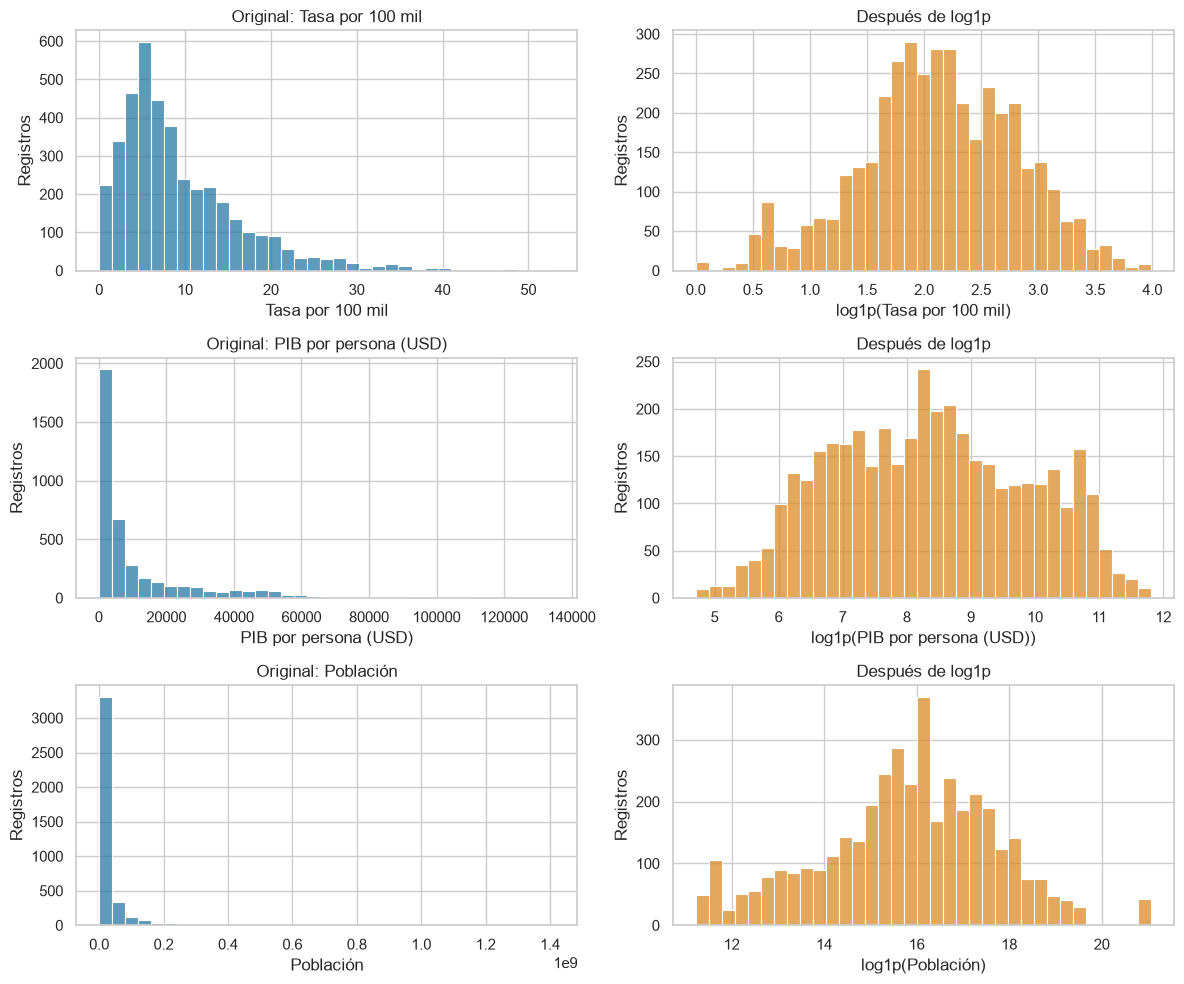

,Variable,Asimetría original,Asimetría log1p,Atípicos IQR original,Atípicos IQR log1p
0,suicide_rate_per_100k,1.6560,-0.2180,173,15
1,gdp_per_capita_usd,2.5300,0.0620,476,0
2,total_country_population,8.1750,-0.2090,457,44


In [3]:
def contar_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    amplitud = q3 - q1
    return int(((serie < q1 - 1.5 * amplitud) | (serie > q3 + 1.5 * amplitud)).sum())

diagnostico = []
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for i, (columna, nombre) in enumerate(zip(variables, nombres)):
    original = base[columna]
    transformada = np.log1p(original)
    diagnostico.append({"Variable": columna, "Asimetría original": original.skew(),
                        "Asimetría log1p": transformada.skew(),
                        "Atípicos IQR original": contar_atipicos(original),
                        "Atípicos IQR log1p": contar_atipicos(transformada)})
    sns.histplot(original, bins=35, ax=axes[i, 0], color="#2878a5")
    sns.histplot(transformada, bins=35, ax=axes[i, 1], color="#da8b28")
    axes[i, 0].set(xlabel=nombre, ylabel="Registros", title=f"Original: {nombre}")
    axes[i, 1].set(xlabel=f"log1p({nombre})", ylabel="Registros", title="Después de log1p")
plt.tight_layout()
plt.show()
display(pd.DataFrame(diagnostico).round(3))


### 3.2 Estandarización Z-score

Sobre las tres variables transformadas aplicamos `StandardScaler`: media 0 y desviación
poblacional 1. K-Means utiliza distancias euclidianas, por lo que el escalado evita que
las unidades monetarias o poblacionales dominen la tasa. Usamos `ddof=0` para comprobar
la misma definición de desviación que emplea el escalador.

Se ajusta el escalador con toda la muestra porque este es un análisis descriptivo de
los registros disponibles. No se presenta como evaluación de predicciones futuras.


In [4]:
# log1p admite tasas iguales a cero y reduce el peso de los extremos.
features = ["log_tasa", "log_pib_per_capita", "log_poblacion"]
X_log = pd.DataFrame(np.log1p(base[variables].to_numpy()),
                     columns=features, index=base.index)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
assert np.isfinite(X_scaled).all()
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0, ddof=0), 1, atol=1e-10)
assert len(np.unique(X_scaled, axis=0)) > max(max(r) for r in RANGOS_K.values())
display(pd.DataFrame({"Variable": features, "Media Z": X_scaled.mean(axis=0),
                      "Desviación Z (ddof=0)": X_scaled.std(axis=0, ddof=0)}))


,Variable,Media Z,Desviación Z (ddof=0)
0,log_tasa,-0.0000,1.0000
1,log_pib_per_capita,-0.0000,1.0000
2,log_poblacion,0.0000,1.0000


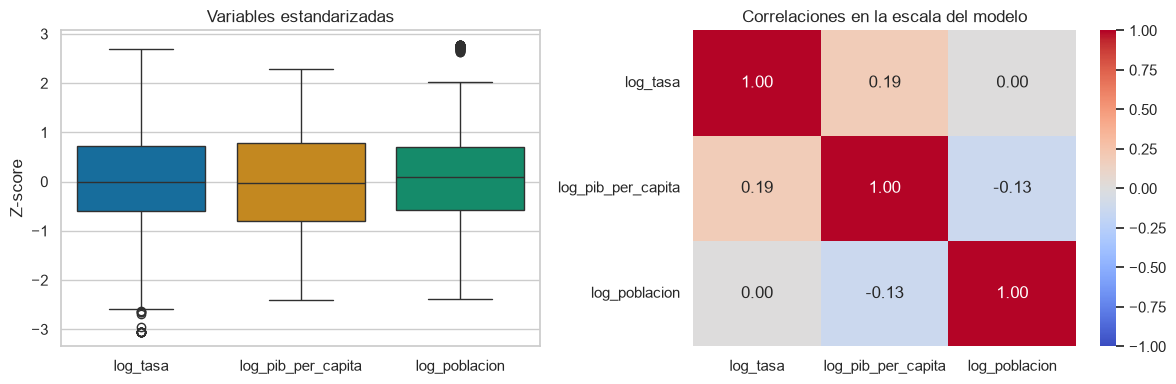

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=pd.DataFrame(X_scaled, columns=features), ax=axes[0])
axes[0].set(title="Variables estandarizadas", ylabel="Z-score")
sns.heatmap(X_log.corr(), annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlaciones en la escala del modelo")
plt.tight_layout()
plt.show()


## 4. Modelos con distintos rangos de K

Se entrenan **14 modelos**, con K de 2 a 15, además de la referencia K=1 para el codo.
Los rangos **bajo (2–5)**, **medio (6–10)** y **amplio (11–15)** permiten comparar
segmentaciones generales frente a otras más detalladas. Todos usan exactamente las
mismas filas, variables, escalado, semilla y número de inicializaciones.

| Indicador | Lectura |
|---|---|
| WCSS o inercia | Menor implica grupos más compactos; suele caer al aumentar K, por lo que no basta para elegir. |
| Reducción WCSS (%) | Mejora frente a K−1, incluso en los límites entre rangos. |
| Silueta | Entre −1 y 1; mayor indica mejor separación relativa. Se calcula sobre toda la muestra. |
| Tamaño mínimo y máximo | Permite detectar fragmentación y grupos muy pequeños. |

**Regla de selección previa:** elegir la mayor silueta entre K=2 y K=15; en caso de
empate exacto, elegir el menor K. El codo y los tamaños de los grupos sirven para
discutir la elección. No se fuerza K=3 por analogía con Calificaciones ni se afirma que
el codo tenga siempre una solución inequívoca. Para K=1 no se define la silueta.


In [6]:
# Se usan todos los registros para calcular las métricas, sin muestreo.
def evaluar_modelos(X):
    modelos, filas = {}, []
    with threadpool_limits(limits=1):
        referencia = KMeans(n_clusters=1, random_state=SEMILLA, n_init=N_INIT).fit(X)
        anterior = referencia.inertia_
        for rango, valores_k in RANGOS_K.items():
            for k in valores_k:
                modelo = KMeans(n_clusters=k, random_state=SEMILLA,
                                n_init=N_INIT, max_iter=500, algorithm="lloyd").fit(X)
                etiquetas = modelo.labels_
                tamanos = np.bincount(etiquetas, minlength=k)
                assert len(np.unique(etiquetas)) == k, "Hay clústeres vacíos."
                assert modelo.n_iter_ < modelo.max_iter, "Revisar convergencia."
                filas.append({
                    "Rango": rango, "K": k, "WCSS": modelo.inertia_,
                    "Reducción WCSS (%)": 100 * (anterior - modelo.inertia_) / anterior,
                    "Silueta": silhouette_score(X, etiquetas),
                    "Grupo mínimo": int(tamanos.min()), "Grupo máximo": int(tamanos.max()),
                    "Grupo mínimo (%)": 100 * tamanos.min() / len(X),
                })
                modelos[k] = modelo
                anterior = modelo.inertia_
    return referencia, modelos, pd.DataFrame(filas)

referencia, modelos, tabla_k = evaluar_modelos(X_scaled)
# Regla explícita: mayor silueta; empate exacto, menor K.
ranking = tabla_k.sort_values(["Silueta", "K"], ascending=[False, True])
k_elegido = int(ranking.iloc[0]["K"])
mejores_rangos = (ranking.drop_duplicates("Rango")
                  .set_index("Rango").loc[list(RANGOS_K)].reset_index())
print(f"Referencia K=1: WCSS={referencia.inertia_:,.2f}; silueta no definida.")
display(tabla_k.round(4))
print("Mejor silueta dentro de cada rango:")
display(mejores_rangos.round(4))
print(f"K seleccionado por la regla declarada: {k_elegido}")


Referencia K=1: WCSS=12,012.00; silueta no definida.


,Rango,K,WCSS,Reducción WCSS (%),Silueta,Grupo mínimo,Grupo máximo,Grupo mínimo (%)
0,Bajo (2–5),2,"8,304.2152",30.8673,0.3026,1958,2046,48.9011
1,Bajo (2–5),3,"6,394.3146",22.9992,0.3103,1030,1793,25.7243
2,Bajo (2–5),4,"5,258.8689",17.7571,0.3062,681,1419,17.0080
3,Bajo (2–5),5,"4,541.9571",13.6324,0.2925,429,1163,10.7143
4,Medio (6–10),6,"4,016.1724",11.5762,0.2873,356,1106,8.8911
5,Medio (6–10),7,"3,655.7693",8.9738,0.2771,319,954,7.9670
6,Medio (6–10),8,"3,312.4621",9.3908,0.2817,311,880,7.7672
7,Medio (6–10),9,"3,038.4486",8.2722,0.2912,293,870,7.3177
8,Medio (6–10),10,"2,825.1732",7.0192,0.2955,215,816,5.3696
9,Amplio (11–15),11,"2,661.5380",5.7920,0.2980,116,778,2.8971


Mejor silueta dentro de cada rango:


,Rango,K,WCSS,Reducción WCSS (%),Silueta,Grupo mínimo,Grupo máximo,Grupo mínimo (%)
0,Bajo (2–5),3,"6,394.3146",22.9992,0.3103,1030,1793,25.7243
1,Medio (6–10),10,"2,825.1732",7.0192,0.2955,215,816,5.3696
2,Amplio (11–15),12,"2,490.7437",6.4171,0.3045,89,784,2.2228


K seleccionado por la regla declarada: 3


## 5. Visualización comparativa y selección de K

La línea vertical marca la elección por silueta. Las franjas distinguen los rangos
ensayados: reducir WCSS con muchos grupos puede producir particiones más fragmentadas
sin mejorar la separación. Se comparan las curvas y la tabla conjuntamente.


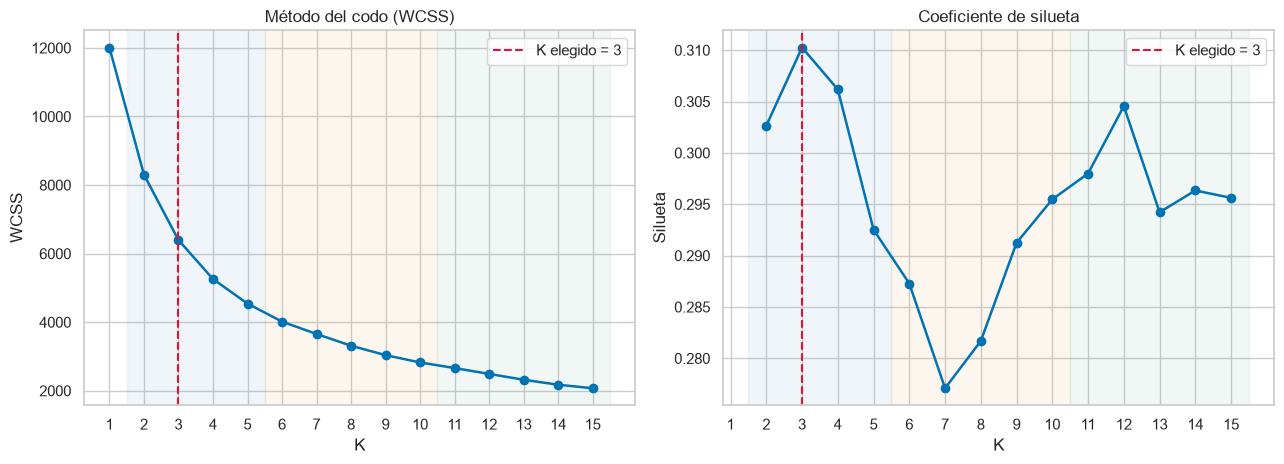

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
curvas = [("WCSS", "Método del codo (WCSS)"),
          ("Silueta", "Coeficiente de silueta")]
for ax, (metrica, titulo) in zip(axes.flat, curvas):
    ks = [1, *tabla_k.K] if metrica == "WCSS" else tabla_k.K
    ys = [referencia.inertia_, *tabla_k.WCSS] if metrica == "WCSS" else tabla_k[metrica]
    ax.plot(ks, ys, "o-", linewidth=1.8)
    for limite_inf, limite_sup, color in [(1.5, 5.5, "#2878a5"),
                                          (5.5, 10.5, "#da8b28"), (10.5, 15.5, "#3b9368")]:
        ax.axvspan(limite_inf, limite_sup, color=color, alpha=0.07)
    ax.axvline(k_elegido, color="crimson", linestyle="--", label=f"K elegido = {k_elegido}")
    ax.set(title=titulo, xlabel="K", ylabel=metrica, xticks=range(1, 16))
    ax.legend()
plt.tight_layout()
plt.show()


In [8]:
ganador = ranking.iloc[0]
segundo = ranking.iloc[1]
lineas = [f"### Lectura de la comparación\n\n"
          f"La mayor silueta corresponde a **K={k_elegido} ({ganador['Silueta']:.4f})**. "
          f"La siguiente es K={int(segundo['K'])} ({segundo['Silueta']:.4f}); "
          f"la diferencia es {ganador['Silueta'] - segundo['Silueta']:.4f}.\n"]
for _, fila in mejores_rangos.iterrows():
    lineas.append(f"- **{fila['Rango']}**: K={int(fila['K'])}, "
                  f"silueta {fila['Silueta']:.4f}, WCSS {fila['WCSS']:,.2f} "
                  f"y grupo mínimo de {int(fila['Grupo mínimo'])} registros "
                  f"({fila['Grupo mínimo (%)']:.2f}%).")
lineas.append("\nEl método del codo permite observar cuánto disminuye la inercia "
              "al aumentar K, mientras que la silueta compara la separación de los grupos. "
              "Una menor WCSS no basta para elegir más clústeres: se mantiene la regla "
              "de mayor silueta y se consideran los tamaños para interpretar la partición. "
              "Los perfiles y la estabilidad se revisan en la Parte 05. "
              "La elección corresponde a las alternativas ensayadas bajo esta "
              "representación, no a un número universal de grupos.")
display(Markdown("\n".join(lineas)))

### Lectura de la comparación

La mayor silueta corresponde a **K=3 (0.3103)**. La siguiente es K=4 (0.3062); la diferencia es 0.0041.

- **Bajo (2–5)**: K=3, silueta 0.3103, WCSS 6,394.31 y grupo mínimo de 1030 registros (25.72%).
- **Medio (6–10)**: K=10, silueta 0.2955, WCSS 2,825.17 y grupo mínimo de 215 registros (5.37%).
- **Amplio (11–15)**: K=12, silueta 0.3045, WCSS 2,490.74 y grupo mínimo de 89 registros (2.22%).

El método del codo permite observar cuánto disminuye la inercia al aumentar K, mientras que la silueta compara la separación de los grupos. Una menor WCSS no basta para elegir más clústeres: se mantiene la regla de mayor silueta y se consideran los tamaños para interpretar la partición. Los perfiles y la estabilidad se revisan en la Parte 05. La elección corresponde a las alternativas ensayadas bajo esta representación, no a un número universal de grupos.

### Interpretación de los resultados obtenidos

En esta ejecución, **K=3** alcanza una silueta de **0,3103**, frente a **0,3062** de K=4 y **0,3045** de K=12. La ventaja es pequeña: se justifica una solución compacta de tres perfiles según la regla declarada, pero no una superioridad concluyente sobre todas las alternativas.

El rango medio obtiene su mejor silueta en **K=10 (0,2955)**. Ampliar a **K=12** reduce la inercia a **2.490,74**, frente a **6.394,31** con K=3, pero introduce un grupo de solo **89 registros (2,22%)**. Es una segmentación más detallada que puede servir para explorar subperfiles; la menor inercia no basta para reemplazar el modelo principal.

La curva del codo muestra una reducción más pronunciada de WCSS en los primeros valores de K y mejoras menores al aumentar la complejidad. Se interpreta junto con la silueta: K=3 ofrece la mayor separación relativa entre las alternativas ensayadas, aunque su ventaja sobre K=4 es pequeña. La Parte 05 evalúa si los tres perfiles se sostienen ante distintas inicializaciones y cuánto cambian al modificar la transformación de la tasa.

*Estas cifras describen la ejecución guardada con el dataset actual; las tablas calculadas deben revisarse si cambia el archivo de entrada.*

## 6. Conclusiones y enlace con la Parte 05

1. La muestra comparable conserva una observación por país y año. Se evita mezclar
   totales con subgrupos superpuestos y se mantiene la cobertura temporal del ETL.
2. Se preservan los extremos válidos. `log1p` y Z-score cambian su peso en la distancia;
   la tabla de asimetrías permite revisar el efecto sin asumir normalidad.
3. La comparación incluye modelos de complejidad baja, media y amplia. La elección
   calculada arriba responde a una regla reproducible y está condicionada a estas tres
   variables, sus transformaciones y los K evaluados.
4. Una silueta positiva no demuestra que existan poblaciones naturales discretas.
   En la Parte 05 se contrastan inicializaciones, perfiles, observaciones con silueta
   negativa y una preparación alternativa antes de interpretar la partición.

**Continuación:** [Parte 05 · K-Means y evaluación](05_KMeans_Evaluacion.ipynb).
Allí se repiten de forma explícita el filtro, las variables y la evaluación para que
ambos documentos funcionen con un kernel nuevo, sin archivos intermedios ocultos.
